# Figuras do trabalho

Gera todas as figuras do relatório e dos slides a partir de `src/grafo.ipynb` e `src/rotas.ipynb` e das tabelas de `resultados/` (rode antes `src/experimento.ipynb`).

| Figura | Arquivo |
|---|---|
| Distância por layout e estratégia | `figuras/fig1_distancia_boxplot.png` |
| Redução entre layouts | `figuras/fig2_reducao_layouts.png` |
| Ganho por número de seções | `figuras/fig3_ganho_faixa_secoes.png` |
| Rotas de um pedido (imagem e GIF) | `figuras/rotas_estrategias`, `figuras/rotas_layouts` |

As imagens dos layouts e dos grafos da modelagem não são geradas aqui: vêm dos scripts `modelagem/gerar_imagens_layouts.py` e `modelagem/gerar_grafos_modelagem.py`.

## Preparação

Carrega a loja, a matriz de distâncias e as estratégias dos notebooks de `src/`, para que as figuras usem exatamente o mesmo modelo do experimento. As cores de layout e de estratégia são fixas em todas as figuras, e os nomes seguem os termos do relatório.

In [1]:
%run ../src/grafo.ipynb
%run ../src/rotas.ipynb

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


COMPARADAS = ESTRATEGIAS[1:]
COMPARACOES = [("L0", "L1"), ("L0", "L2"), ("L2", "L1")]  # (base, novo)

FIGURAS = PASTA_PROJETO / "figuras"

PRETO, CINZA, CINZA_CLARO, GRADE, BRANCO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#ffffff"
VERDE, VERMELHO = "#2ca02c", "#d62728"
COR_LAYOUT = {"L0": "#2a78d6", "L1": "#eb6834", "L2": "#1baf7a"}
COR_ESTRATEGIA = {"ordem_carrinho": CINZA_CLARO, "corredores": "#6250d6", "vizinho": "#008300", "custoMin": "#e87ba4"}
NOME_LAYOUT = {"L0": "aleatório", "L1": "afinidade", "L2": "popularidade"}
NOME_ESTRATEGIA = {"ordem_carrinho": "ordem do carrinho", "corredores": "varredura em S",
                   "vizinho": "vizinho mais próximo", "custoMin": "custo mínimo"}

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.labelcolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
    "figure.facecolor": BRANCO, "savefig.facecolor": BRANCO,
})


def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png", dpi=200)


def coordenadas(vertices):
    xs, ys = zip(*(loja.coordenadas[v] for v in vertices))
    return list(xs), list(ys)

## Resultados do experimento

### Distância por layout e estratégia

Caixa = quartis, linha branca = mediana, losango = média.

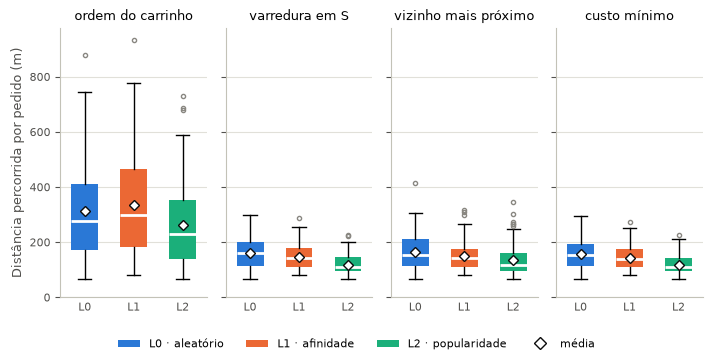

In [2]:
resultados = pd.read_csv(PASTA_RESULTADOS / "resultados_por_pedido.csv").sort_values("id_teste")

fig, eixos = plt.subplots(1, len(ESTRATEGIAS), sharey=True, figsize=(7.2, 3.6))
for eixo, estrategia in zip(eixos, ESTRATEGIAS):
    por_layout = [resultados[(resultados["estrategia"] == estrategia) & (resultados["layout"] == layout)]["distancia_m"]
                  for layout in LAYOUTS]
    caixas = eixo.boxplot(por_layout, positions=range(3), widths=0.55, patch_artist=True, showmeans=True,
                          boxprops={"linewidth": 0}, medianprops={"color": BRANCO, "linewidth": 2},
                          flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "none",
                                      "markeredgecolor": CINZA_CLARO},
                          meanprops={"marker": "D", "markersize": 5.5, "markerfacecolor": BRANCO,
                                     "markeredgecolor": PRETO})
    for caixa, layout in zip(caixas["boxes"], LAYOUTS):
        caixa.set_facecolor(COR_LAYOUT[layout])
    eixo.set_xticks(range(3), LAYOUTS)
    eixo.set_title(NOME_ESTRATEGIA[estrategia])
    eixo.set_ylim(bottom=0)
    eixo.tick_params(axis="x", length=0)
    eixo.yaxis.grid(True, color=GRADE)
    eixo.set_axisbelow(True)

eixos[0].set_ylabel("Distância percorrida por pedido (m)")
legenda = [Patch(facecolor=COR_LAYOUT[l], label=f"{l} · {NOME_LAYOUT[l]}") for l in LAYOUTS]
legenda.append(Line2D([], [], marker="D", ls="", markerfacecolor=BRANCO, markeredgecolor=PRETO, label="média"))
fig.legend(handles=legenda, loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.08, 1, 1))
salvar(fig, "fig1_distancia_boxplot")
plt.show()

### Redução de distância entre layouts

Ponto = redução da distância média; barra = IC de 95%. Ponto cheio quando o intervalo não contém o zero.

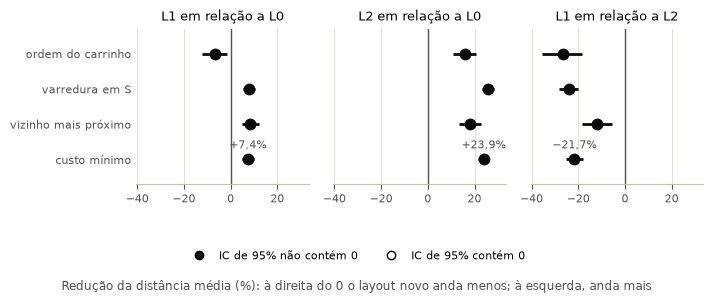

In [3]:
reducao = pd.read_csv(PASTA_RESULTADOS / "tabela_reducao_layouts.csv")
altura = {e: len(ESTRATEGIAS) - 1 - i for i, e in enumerate(ESTRATEGIAS)}
menor, maior = reducao["ic_inf_pct"].min(), reducao["ic_sup_pct"].max()
folga = 0.08 * (maior - menor)

fig, eixos = plt.subplots(1, len(COMPARACOES), sharex=True, sharey=True, figsize=(7.2, 3.0))
for eixo, (base, novo) in zip(eixos, COMPARACOES):
    tabela = reducao[reducao["comparacao"] == f"{novo} vs {base}"].set_index("estrategia")
    eixo.axvline(0, color=CINZA, lw=1)
    for estrategia, linha in tabela.iterrows():
        significativo = linha["ic_inf_pct"] > 0 or linha["ic_sup_pct"] < 0
        y = altura[estrategia]
        eixo.hlines(y, linha["ic_inf_pct"], linha["ic_sup_pct"], color=PRETO, lw=2)
        eixo.plot(linha["reducao_pct"], y, "o", markersize=7, markeredgewidth=1.5, markeredgecolor=PRETO,
                  markerfacecolor=PRETO if significativo else BRANCO)
        if estrategia == "custoMin":
            rotulo = f"{linha['reducao_pct']:+.1f}%".replace(".", ",").replace("-", "−")
            eixo.annotate(rotulo, (linha["reducao_pct"], y), xytext=(0, 8), textcoords="offset points",
                          ha="center", fontsize=8, color=CINZA)
    eixo.set_title(f"{novo} em relação a {base}")
    eixo.set_yticks(list(altura.values()), [NOME_ESTRATEGIA[e] for e in altura])
    eixo.set(ylim=(-0.7, len(ESTRATEGIAS) - 0.3), xlim=(menor - folga, maior + folga))
    eixo.spines["left"].set_visible(False)
    eixo.tick_params(axis="y", length=0)
    eixo.xaxis.grid(True, color=GRADE)
    eixo.set_axisbelow(True)

fig.supxlabel("Redução da distância média (%): à direita do 0 o layout novo anda menos; à esquerda, anda mais",
              fontsize=8.5, color=CINZA, y=0.01)
legenda = [Line2D([], [], ls="", marker="o", markerfacecolor=cor, markeredgecolor=PRETO, label=texto)
           for cor, texto in ((PRETO, "IC de 95% não contém 0"), (BRANCO, "IC de 95% contém 0"))]
fig.legend(handles=legenda, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.08))
fig.tight_layout(rect=(0, 0.17, 1, 1))
salvar(fig, "fig2_reducao_layouts")
plt.show()

### Ganho contra a ordem do carrinho por número de seções

Cada faixa tem poucos pedidos, então os intervalos são largos: o que importa é a tendência.

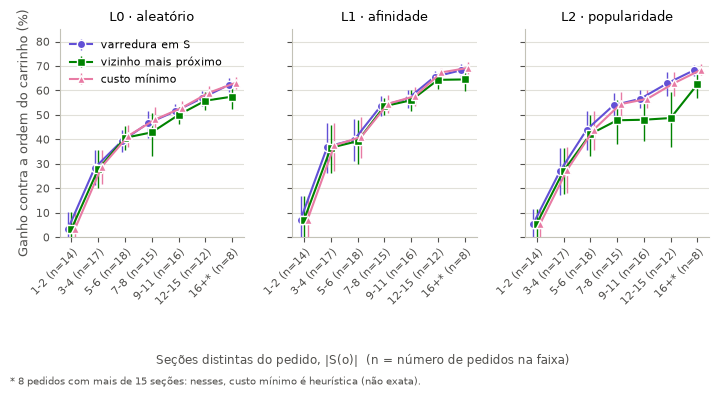

In [4]:
ganhos = pd.read_csv(PASTA_RESULTADOS / "tabela_ganho_faixa_secoes.csv")
faixas = list(dict.fromkeys(ganhos["faixa_secoes"]))
deslocamento = dict(zip(COMPARADAS, (-0.13, 0, 0.13)))
marcador = dict(zip(COMPARADAS, "os^"))
rotulos = []
for faixa in faixas:
    linhas = ganhos[ganhos["faixa_secoes"] == faixa]
    asterisco = "*" if (linhas["n_pedidos_heuristicos"] > 0).any() else ""
    rotulos.append(f"{faixa}{asterisco} (n={linhas['n_pedidos'].iloc[0]})")

fig, eixos = plt.subplots(1, len(LAYOUTS), sharex=True, sharey=True, figsize=(7.2, 3.9))
for eixo, layout in zip(eixos, LAYOUTS):
    for estrategia in COMPARADAS:
        serie = ganhos[(ganhos["layout"] == layout) & (ganhos["estrategia"] == estrategia)]
        x = np.array([faixas.index(f) for f in serie["faixa_secoes"]]) + deslocamento[estrategia]
        media = serie["ganho_medio_pct"].to_numpy()
        erro = [media - serie["ic_inf_pct"], serie["ic_sup_pct"] - media]
        eixo.errorbar(x, media, yerr=erro, color=COR_ESTRATEGIA[estrategia], marker=marcador[estrategia],
                      markersize=6, markeredgecolor=BRANCO, lw=1.5, elinewidth=1, label=NOME_ESTRATEGIA[estrategia])
    eixo.set_title(f"{layout} · {NOME_LAYOUT[layout]}")
    eixo.set_xticks(range(len(faixas)), rotulos, rotation=45, ha="right", rotation_mode="anchor")
    eixo.set_ylim(0, np.ceil(ganhos["ic_sup_pct"].max() / 10) * 10 + 5)
    eixo.yaxis.grid(True, color=GRADE)
    eixo.set_axisbelow(True)

eixos[0].set_ylabel("Ganho contra a ordem do carrinho (%)")
eixos[0].legend(loc="upper left")
fig.supxlabel("Seções distintas do pedido, |S(o)|  (n = número de pedidos na faixa)",
              fontsize=8.5, color=CINZA, y=0.05)
n_heuristicos = int(ganhos["n_pedidos_heuristicos"].max())
fig.text(0.01, 0.005,
         f"* {n_heuristicos} pedidos com mais de 15 seções: nesses, custo mínimo é heurística (não exata).",
         fontsize=7.5, color=CINZA)
fig.tight_layout(rect=(0, 0.1, 1, 1))
salvar(fig, "fig3_ganho_faixa_secoes")
plt.show()

## Rotas de um pedido

O mesmo pedido percorrido pelas quatro estratégias (no layout L0) e pela rota ótima nos três layouts. Cada trecho segue o caminho mínimo pelos corredores. O GIF mostra as rotas sendo percorridas na mesma velocidade.

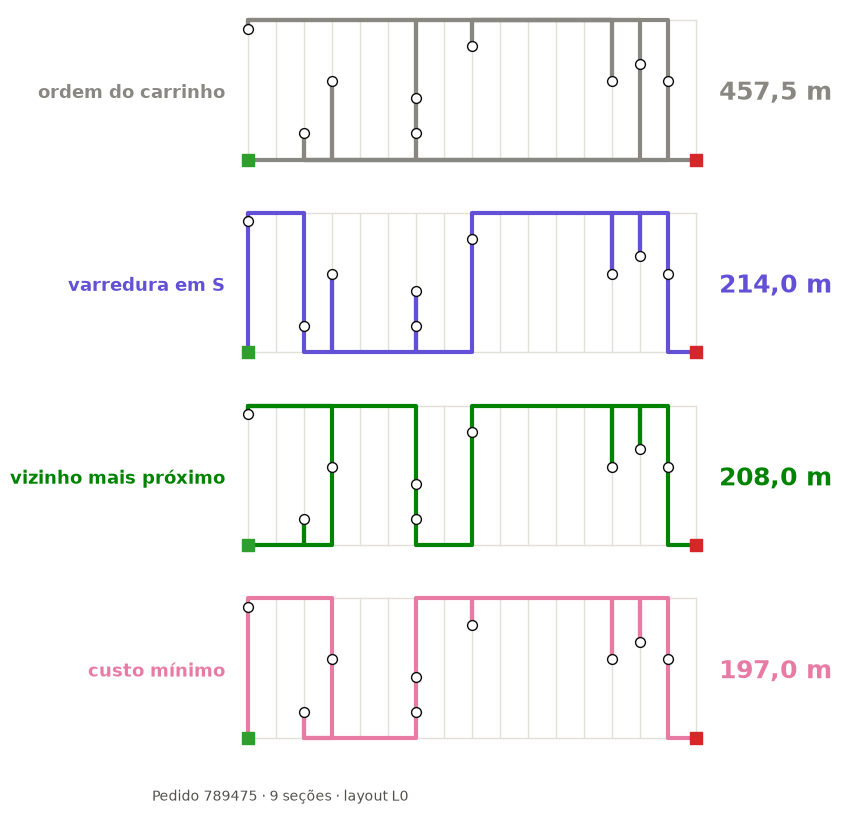

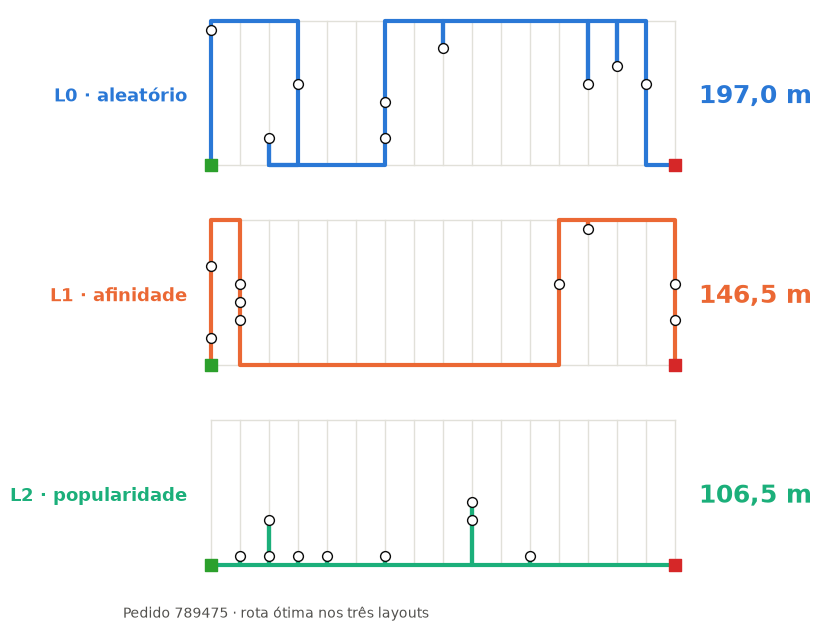

In [5]:
PEDIDO = 789475
pedido = pedidos.set_index("order_id").loc[PEDIDO]


def trajeto(ordem):
    paradas = [loja.ENTRADA] + list(ordem) + [loja.CAIXA]
    pontos = [loja.coordenadas[loja.ENTRADA]]
    for a, b in zip(paradas, paradas[1:]):
        pontos += loja.caminho(a, b)[1:]
    return np.array(pontos)


def ate_a_distancia(pontos, metros):
    passos = np.abs(np.diff(pontos, axis=0)).sum(axis=1)
    andado = np.concatenate([[0], np.cumsum(passos)])
    k = np.searchsorted(andado, metros, side="right")
    if k >= len(pontos):
        return pontos
    fracao = (metros - andado[k - 1]) / passos[k - 1]
    return np.vstack([pontos[:k], pontos[k - 1] + fracao * (pontos[k] - pontos[k - 1])])


def painel(layout, estrategia, rotulo, cor):
    slots = slots_do_pedido(pedido["secoes"], carregar_layout(layout), loja)
    ordem, metros = executar(estrategia, slots, distancias, loja)
    return {"rotulo": rotulo, "cor": cor, "slots": slots, "pontos": trajeto(ordem), "metros": metros}


def desenhar_rotas(paineis, nome, rodape):
    fig, eixos = plt.subplots(len(paineis), 1, figsize=(10, 1.9 * len(paineis) + 0.6))
    fig.subplots_adjust(left=0.2, right=0.84, top=0.98, bottom=0.07, hspace=0.15)
    linhas, textos = [], []
    for eixo, p in zip(eixos, paineis):
        for x in sorted({x for x, _ in loja.coordenadas}):
            eixo.plot([x, x], [ALTURA_FRENTE, ALTURA_FUNDO], color=GRADE, lw=1)
        eixo.plot([0, 64], [ALTURA_FRENTE] * 2, color=GRADE, lw=1)
        eixo.plot([0, 64], [ALTURA_FUNDO] * 2, color=GRADE, lw=1)
        eixo.scatter(*coordenadas(p["slots"]), s=50, facecolor=BRANCO, edgecolor=PRETO, zorder=5)
        eixo.scatter(*coordenadas([loja.ENTRADA]), marker="s", s=80, color=VERDE, zorder=6)
        eixo.scatter(*coordenadas([loja.CAIXA]), marker="s", s=80, color=VERMELHO, zorder=6)
        eixo.text(-0.02, 0.5, p["rotulo"], transform=eixo.transAxes, ha="right", va="center",
                  fontsize=13, color=p["cor"], fontweight="bold")
        linhas.append(eixo.plot([], [], color=p["cor"], lw=3, zorder=4)[0])
        textos.append(eixo.text(1.02, 0.5, "", transform=eixo.transAxes, va="center", fontsize=18,
                                color=p["cor"], fontweight="bold"))
        eixo.set(xlim=(-2, 66), ylim=(-2.5, 21.5), aspect="equal")
        eixo.axis("off")
    fig.text(0.2, 0.015, rodape, fontsize=10, color=CINZA)

    maior = max(p["metros"] for p in paineis)
    n_quadros = 120

    def quadro(i):
        metros = maior * min(1, i / (n_quadros - 30))
        for linha, texto, p in zip(linhas, textos, paineis):
            parte = ate_a_distancia(p["pontos"], min(metros, p["metros"]))
            linha.set_data(parte[:, 0], parte[:, 1])
            texto.set_text(f"{min(metros, p['metros']):.1f} m".replace(".", ","))
        return linhas + textos

    FuncAnimation(fig, quadro, frames=n_quadros).save(FIGURAS / f"{nome}.gif", writer=PillowWriter(fps=20))
    quadro(n_quadros - 1)
    salvar(fig, nome)
    plt.show()


estrategias = [painel("L0", e, NOME_ESTRATEGIA[e], COR_ESTRATEGIA[e]) for e in ESTRATEGIAS]
desenhar_rotas(estrategias, "rotas_estrategias",
               f"Pedido {PEDIDO} · {len(estrategias[0]['slots'])} seções · layout L0")

layouts = [painel(l, "custoMin", f"{l} · {NOME_LAYOUT[l]}", COR_LAYOUT[l]) for l in LAYOUTS]
desenhar_rotas(layouts, "rotas_layouts", f"Pedido {PEDIDO} · rota ótima nos três layouts")